In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Open this notebook from the project folder or its notebooks folder')
sys.path.insert(0, str(ROOT))
import pandas as pd
from src.data import QSARDataLoader, FEATURE_NAMES
import matplotlib.pyplot as plt


In [2]:

loader = QSARDataLoader(ROOT / 'Data')
qsar = loader.load(download=True)
raw = pd.read_csv(loader.path, sep=';', header=None)
raw.columns = FEATURE_NAMES + ['target']
print('Raw:', raw.shape, 'Duplicates:', raw.duplicated().sum())
print('After cleaning:', len(qsar.y), 'samples and', qsar.X.shape[1], 'features')
print('Missing values:', int(raw.isna().sum().sum()))
print('Class counts:', raw.drop_duplicates()['target'].value_counts().to_dict())
display(raw.head())

Raw: (1055, 42) Duplicates: 3
After cleaning: 1052 samples and 41 features
Missing values: 0
Class counts: {'NRB': 698, 'RB': 354}


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,F03[C-N],SdssC,HyWi_B(m),LOC,SM6_L,F03[C-O],Me,Mi,nN-N,nArNO2,nCRX3,SpPosA_B(p),nCIR,B01[C-Br],B03[C-Cl],N-073,SpMax_A,Psi_i_1d,B04[C-Br],SdO,TI2_L,nCrt,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,target
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,0,0.000,3.106,2.550,9.002,0,0.960,1.142,0,0,0,1.201,0,0,0,0,1.932,0.011,0,0.000,4.489,0,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,0,0.000,2.461,1.393,8.723,1,0.989,1.144,0,0,0,1.104,1,0,0,0,2.214,-0.204,0,0.000,1.542,0,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,0,0.000,3.279,2.585,9.110,0,1.009,1.152,0,0,0,1.092,0,0,0,0,1.942,-0.008,0,0.000,4.891,0,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,0,0.000,2.100,0.918,6.594,0,1.108,1.167,0,0,0,1.024,0,0,0,0,1.414,1.073,0,8.361,1.333,0,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,0,-0.271,3.449,2.753,9.528,2,1.004,1.147,0,0,0,1.137,0,0,0,0,1.985,-0.002,0,10.348,5.588,0,0,0,0,3.351,2.405,0,8.003,0,0,RB


,count,mean,std,min,25%,50%,75%,max
SpMax_L,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
J_Dz(e),1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
nHM,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
F01[N-N],1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
F04[C-N],1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
NssssC,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
nCb-,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
C%,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000
nCp,1055.0,1.376303,1.963521,0.0000,0.00000,1.0000,2.00000,24.0000
nO,1055.0,1.803791,1.775435,0.0000,0.00000,2.0000,3.00000,12.0000


Constant features: []


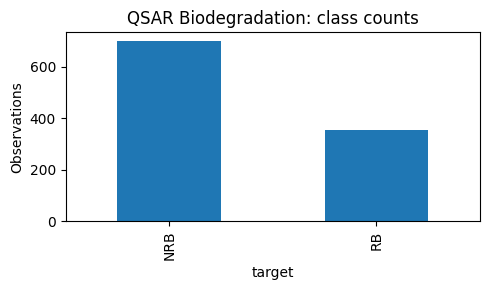

In [3]:
display(raw.describe().T.head(12))
print('Constant features:', [c for c in FEATURE_NAMES if raw[c].nunique() <= 1])
raw.target.value_counts().reindex(['NRB','RB']).plot(kind='bar', figsize=(5,3))
plt.title('QSAR Biodegradation: class counts')
plt.ylabel('Observations')
plt.tight_layout()
plt.show()
